# Dataset rekomendasi: kejarangan, k-core, dan long-tail

[![Buka di Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/imamrozi/recsys-hibrida-multisinyal-notebooks/blob/main/notebooks/bab01_lanskap/01_dataset_kejarangan_longtail.ipynb)

**Buku pendamping:** *Sistem Rekomendasi Hibrida Multi-Sinyal: Rating, Sentimen, dan Emosi* · Bab 1 · Kode 1.5.1 dan 1.5.2

**Tujuan belajar**

- Mengukur ukuran, densitas, dan sparsity matriks interaksi.
- Memahami bahwa k-core filtering mengubah dataset, bukan sekadar membersihkannya.
- Melihat bagaimana kemiringan long-tail membuat baseline popularitas tampak kuat.

> **Catatan jujur.** Semua data di notebook ini **simulasi** dan dibuat agar mudah dijalankan (CPU, hitungan detik). Angka yang keluar menunjukkan *perilaku metode*, bukan hasil empiris pada dataset nyata, dan tidak boleh dikutip sebagai bukti. Kode bersifat ilustratif dan **belum production-ready** (tanpa validasi masukan, tanpa uji beban).

## 1. Kode dari buku

Tiga fungsi: pembangkit data simulasi long-tail (Zipf), statistik dasar, dan k-core.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def simulate_interactions(n_users=2000, n_items=3000, n_events=60000,
                          alpha=1.0, seed=7):
    """Data tiruan: popularitas item mengikuti pola long-tail (Zipf)."""
    rng = np.random.default_rng(seed)
    w = 1.0 / np.arange(1, n_items + 1) ** alpha     # bobot per peringkat
    items = rng.choice(n_items, size=n_events, p=w / w.sum())
    users = rng.integers(0, n_users, size=n_events)
    ratings = rng.choice([1, 2, 3, 4, 5], size=n_events,
                         p=[.05, .05, .10, .30, .50])
    df = pd.DataFrame({"user": users, "item": items, "rating": ratings})
    return df.drop_duplicates(["user", "item"]).reset_index(drop=True)


def dataset_stats(df):
    """Statistik dasar: ukuran, densitas, sparsity, dan rata-rata rating."""
    m, n, k = df["user"].nunique(), df["item"].nunique(), len(df)
    return {"users": m, "items": n, "interactions": k,
            "density_pct": 100 * k / (m * n),
            "sparsity_pct": 100 * (1 - k / (m * n)),
            "mean_rating": df["rating"].mean()}


def k_core(df, k=5):
    """Buang pengguna dan item dengan < k interaksi, ulangi sampai stabil."""
    while True:
        n_user = df["user"].map(df["user"].value_counts())
        n_item = df["item"].map(df["item"].value_counts())
        keep = (n_user >= k) & (n_item >= k)
        if keep.all():
            return df
        df = df[keep]


def popularity_curve(df):
    """Jumlah interaksi per item (urut menurun) dan porsi kumulatifnya."""
    counts = df["item"].value_counts().to_numpy()         # sudah menurun
    share = counts.cumsum() / counts.sum()
    return counts, share


def plot_long_tail(df, head=0.10):
    counts, share = popularity_curve(df)
    n = len(counts)
    rank = np.arange(1, n + 1)
    h = int(np.ceil(head * n))                      # banyak item "kepala"
    fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.4))
    a.loglog(rank, counts)
    a.set(xlabel="Peringkat item (log)", ylabel="Interaksi per item (log)")
    b.plot(rank / n, share)
    b.axvline(head, ls="--", c="gray")
    b.set(xlabel="Fraksi item teratas", ylabel="Porsi kumulatif interaksi")
    fig.tight_layout()
    return fig, float(share[h - 1])                 # porsi milik item kepala

## 2. Jalankan seperti di buku

Mentah vs 5-core: perhatikan jumlah pengguna dan item yang hilang.

In [2]:
raw = simulate_interactions()
core = k_core(raw, 5)
tabel = pd.DataFrame({"mentah": dataset_stats(raw), "5-core": dataset_stats(core)}).T
tabel.round(3)

,users,items,interactions,density_pct,sparsity_pct,mean_rating
mentah,2000.0,2921.0,49181.0,0.842,99.158,4.159
5-core,2000.0,1665.0,45837.0,1.376,98.624,4.160


10% item teratas = 63.4% interaksi


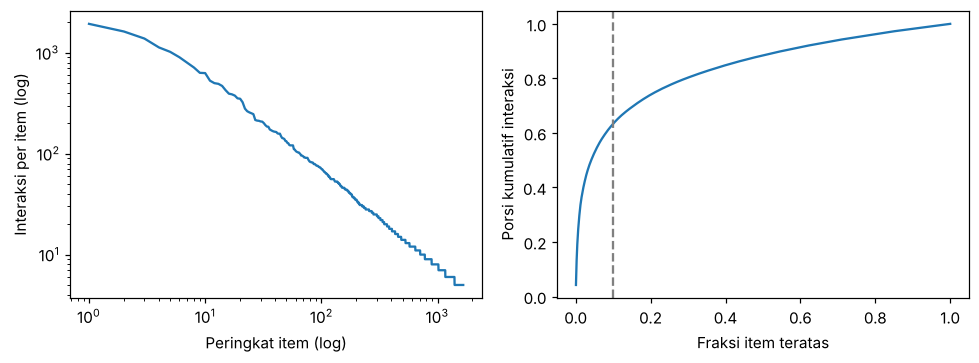

In [3]:
fig, head_share = plot_long_tail(core)
print(f"10% item teratas = {100 * head_share:.1f}% interaksi")

## 3. Eksperimen A: seberapa kuat k-core mengubah dataset?

Naikkan *k* dan amati berapa persen interaksi, pengguna, dan item yang bertahan. Pada data yang sangat *long-tail*, sebagian besar item berada di ekor dan terbuang lebih dulu.

In [4]:
rows = []
for k in (1, 3, 5, 10, 15, 20):
    d = k_core(raw, k)
    if len(d) == 0:                      # k terlalu tinggi: dataset habis
        rows.append({"k": k, "interaksi_%": 0.0, "pengguna_%": 0.0,
                     "item_%": 0.0, "densitas_%": float("nan")})
        continue
    s = dataset_stats(d)
    rows.append({"k": k, "interaksi_%": 100 * s["interactions"] / len(raw),
                 "pengguna_%": 100 * s["users"] / raw["user"].nunique(),
                 "item_%": 100 * s["items"] / raw["item"].nunique(),
                 "densitas_%": s["density_pct"]})
hasil_k = pd.DataFrame(rows).set_index("k")
print(hasil_k.round(2))

# Klaim yang diuji: item terbuang jauh lebih cepat daripada interaksi
r10 = hasil_k.loc[10]
assert r10["item_%"] < r10["interaksi_%"]

    interaksi_%  pengguna_%  item_%  densitas_%
k                                              
1        100.00      100.00  100.00        0.84
3         98.22      100.00   81.27        1.02
5         93.20      100.00   57.00        1.38
10        81.39       99.95   26.60        2.58
15        64.35       83.10   15.10        4.32
20         0.00        0.00    0.00         NaN


**Interpretasi.** Pada data ini item menyusut jauh lebih cepat daripada interaksi: ekor panjang berisi banyak item yang jarang disentuh. Pada *k* = 20 dataset simulasi ini habis sama sekali. Konsekuensinya, hasil evaluasi pada dataset ter-*filter* **tidak sebanding** dengan dataset mentah. Selalu laporkan *k* yang dipakai.

## 4. Eksperimen B: kemiringan long-tail dan baseline popularitas

Parameter `alpha` mengatur kemiringan Zipf. Uji sederhana *leave-one-out*: satu interaksi tiap pengguna disembunyikan, lalu kita merekomendasikan 10 item terpopuler dari sisanya. Jika *hit rate* naik tajam bersama `alpha`, baseline popularitas bisa tampak "pintar" hanya karena data yang miring.

In [5]:
def popularity_hit_rate(df, K=10, seed=0):
    """Sembunyikan 1 interaksi per pengguna, rekomendasikan K item terpopuler."""
    n = df["user"].value_counts()
    d = df[df["user"].isin(n[n >= 2].index)]
    held = d.groupby("user").sample(1, random_state=seed)
    train = d.drop(held.index)
    top = train["item"].value_counts().index[:K]
    return held["item"].isin(top).mean()


rows = []
for alpha in (0.0, 0.5, 0.8, 1.0, 1.2):
    d = k_core(simulate_interactions(alpha=alpha), 5)
    _, share = popularity_curve(d)
    h = int(np.ceil(0.10 * len(share)))
    rows.append({"alpha": alpha, "porsi_10%_teratas": share[h - 1],
                 "hit_rate@10_populer": popularity_hit_rate(d),
                 "hit_rate@10_acak": 10 / d["item"].nunique()})
hasil_alpha = pd.DataFrame(rows).set_index("alpha")
print(hasil_alpha.round(4))

assert hasil_alpha["hit_rate@10_populer"].is_monotonic_increasing

       porsi_10%_teratas  hit_rate@10_populer  hit_rate@10_acak
alpha                                                          
0.0               0.1412               0.0030            0.0033
0.5               0.3077               0.0390            0.0034
0.8               0.5123               0.1355            0.0038
1.0               0.6341               0.2470            0.0060
1.2               0.7132               0.3485            0.0118


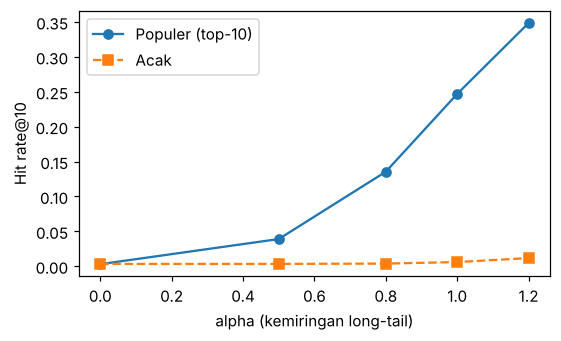

In [6]:
fig, ax = plt.subplots(figsize=(5.2, 3.2))
ax.plot(hasil_alpha.index, hasil_alpha["hit_rate@10_populer"], "o-", label="Populer (top-10)")
ax.plot(hasil_alpha.index, hasil_alpha["hit_rate@10_acak"], "s--", label="Acak")
ax.set(xlabel="alpha (kemiringan long-tail)", ylabel="Hit rate@10")
ax.legend()
fig.tight_layout()

**Interpretasi (dari data simulasi ini).** Makin miring distribusinya, makin tinggi hit rate baseline populer, sementara baseline acak tetap sangat rendah. Di sini perilaku pengguna tidak personal (item dipilih hanya menurut popularitas), jadi popularitas *kebetulan* menjadi prediktor terbaik. Pada data nyata ada selera individual. Karena itu model personal harus dibandingkan dengan baseline populer, bukan hanya dengan acak, sebelum diklaim "bekerja".

## 5. Coba sendiri

Ubah `alpha`, `n_items`, atau `n_events` pada `simulate_interactions`. Pantau kapan k-core membuang hampir semua item.

## Pertanyaan refleksi

1. Mengapa densitas naik setelah k-core, padahal tidak ada data yang ditambahkan?
2. Apa yang terjadi pada hit rate baseline populer jika `alpha = 0`? Apa artinya bagi dataset yang hampir seragam?
3. Mengapa baseline populer wajib ada pada tabel hasil eksperimen sistem rekomendasi?